# Step 3: Measuring Cell Morphology

`cellmate.image_measure.ImageMeasure` turns a single labeled instance mask
(one 2D image, e.g. one frame of step 2's tracked movie) into:

* a **table** of per-cell morphology -- area, major/minor axis length,
  eccentricity, skeleton ("medial axis") length, and more, and
* **spatial-relationship queries** between pairs of cells -- nearest
  neighbor, distance, contact angle -- the kind of features used to decide
  whether two cells are touching/mating.

Because it operates on a single mask, it works equally well on one frame at
a time (this notebook) or looped over every frame of a movie to build a
per-cell time series (section 4 below).

A command-line equivalent (`03_measure_image.py`) is included in this same
folder.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from skimage.io import imread
from tqdm.notebook import trange

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "cellmate").is_dir())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from cellmate.image_measure import ImageMeasure
from cellmate.visualize import label2rgb

print("cellmate loaded from:", REPO_ROOT / "cellmate")

cellmate loaded from: /home/wlli/project/CellMate/cellmate


## 1. Load a single labeled mask

mask shape: (250, 250) labels: [1001 1002 1003 1004]


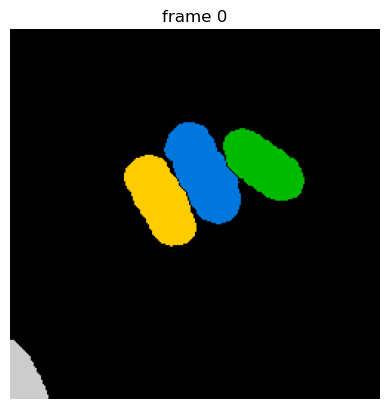

In [2]:
input_path = REPO_ROOT / "demo" / "YAV2104xYAV2105_20220826_exp011_05_R3D_rigid_003002.tif"
image = imread(str(input_path))
mask = image[0, -1]  # first frame's instance mask
print("mask shape:", mask.shape, "labels:", np.unique(mask)[1:])

plt.imshow(label2rgb(mask))
plt.title("frame 0")
plt.axis("off")
plt.show()

## 2. Build the property table

* `pixel_size` -- physical size of one pixel (e.g. microns/pixel); length
  and area columns get scaled by it. Left at `1` here since this dataset's
  calibration isn't bundled with the demo; set it to your microscope's real
  value for physical units.
* `sampling_interval` -- spacing (in pixels) used when re-sampling each
  cell's contour/skeleton; lower is finer but slower.
* `equidistant` -- re-sample contour points at equal arc-length spacing
  (recommended; makes contour indices comparable between cells).

In [3]:
measure = ImageMeasure(mask, pixel_size=1.0, sampling_interval=5, skeleton_ecc_threshold=0.9, equidistant=True)
measure.property_table

,label,orientation,axis_major_length,axis_minor_length,area,eccentricity,coords,skeleton,skeleton_minor_axis,skeleton_minor_grid,...,skeleton_center,centroid_0,centroid_1,bbox_0,bbox_1,bbox_2,bbox_3,semantic,instance,is_out_of_border
0,1001,2.656757,77.134855,36.667165,2194.0,0.879789,"[[63.95010305329846, 114.1222433598427], [62.6...","[[63.8074092461966, 114.46495520981986], [67.7...","[[89.16638017568981, 145.01589889238014], [104...","[[[62.661745313471364, 122.4081173787784], [68...",...,"[96.93519889073987, 129.99522980827967]",96.882862,130.303099,63,104,132,156,1,1,0
1,1002,2.220789,64.755959,33.525738,1696.0,0.855547,"[[71.11318184012045, 146.43733032786733], [68....","[[72.28516414997742, 145.2960947039499], [74.9...","[[79.14856780869383, 179.8500856353027], [104....","[[[67.84206541150591, 151.50035170126716], [77...",...,"[91.89074915429502, 170.26401740026148]",91.669222,170.650943,67,144,116,199,1,2,0
2,1003,2.627674,69.981922,34.516115,1877.0,0.869908,"[[86.9331044710678, 85.15529352273101], [85.17...","[[86.94862270479629, 85.12403576287883], [90.7...","[[107.27266864577243, 115.77396275031498], [12...","[[[84.72764353490633, 93.59023407903436], [93....",...,"[115.49493454011247, 101.90147792054076]",115.301545,101.385722,85,77,147,126,1,3,0
3,1004,2.784491,43.093236,22.502949,680.0,0.852828,"[[210.4151762821769, 2.515506544935213], [213....","[[208.90366562173432, 1.948061131257996], [213...","[[227.673208648987, 16.517411943582424], [237....","[[[211.08277460894448, 3.3405812774938646], [2...",...,"[232.43542998577428, 7.977665778016865]",233.973529,9.317647,210,0,250,26,1,4,1


In [4]:
measure.property_table["coords"]

0    [[63.95010305329846, 114.1222433598427], [62.6...
1    [[71.11318184012045, 146.43733032786733], [68....
2    [[86.9331044710678, 85.15529352273101], [85.17...
3    [[210.4151762821769, 2.515506544935213], [213....
Name: coords, dtype: object

A few columns worth knowing:

* `label` = `semantic * 1000 + instance` (see step 2's notebook),
* `skeleton_major_length` -- length of the cell's medial axis, a good proxy
  for a yeast cell's long-axis length,
* `is_out_of_border` -- `True` if the cell touches the image edge (often
  excluded from quantitative analysis since it may be partially cropped).

## 3. Visualize the geometry behind the numbers

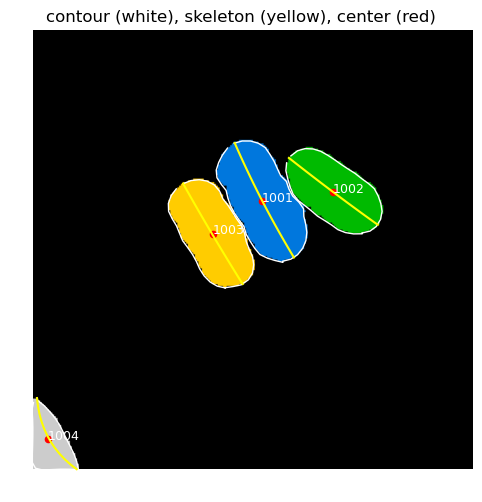

In [5]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(label2rgb(mask))
for i, label in enumerate(measure.labels.astype(int)):
    contour = measure.coordinate(index=i)
    skeleton = measure.skeleton(index=i)
    center = measure.center(index=i)
    ax.plot(contour[:, 1], contour[:, 0], "-", lw=1, color="white")
    ax.plot(skeleton[:, 1], skeleton[:, 0], "-", lw=1.5, color="yellow")
    ax.scatter(center[1], center[0], c="red", s=20)
    ax.text(center[1], center[0], str(label), color="white", fontsize=9)
ax.set_title("contour (white), skeleton (yellow), center (red)")
ax.axis("off")
plt.show()

## 4. Spatial relationships between cells

`neighbor`, `distance`, `nearest_point`, `between_angle` and
`adjacent_matrix` answer questions about how cells relate to each other --
useful for finding candidate mating pairs (cells in contact) independent of
the tracking-based fusion detection from step 2.

cell 1001's neighbors: [1002, 1003]


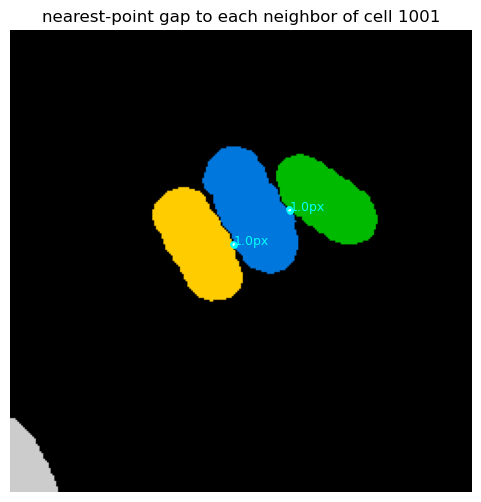

In [6]:
cell_index = 0
neighbor_indices = measure.neighbor(cell_index)
print(f"cell {int(measure.labels[cell_index])}'s neighbors:",
     [int(measure.labels[n]) for n in neighbor_indices])

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(label2rgb(mask))
for neighbor_index in neighbor_indices:
    target_point, source_point = measure.nearest_point(cell_index, neighbor_index)
    gap = measure.distance(cell_index, neighbor_index)[0, 0, 1]
    ax.plot([source_point[1], target_point[1]], [source_point[0], target_point[0]],
           "w--", lw=2)
    ax.scatter([source_point[1], target_point[1]], [source_point[0], target_point[0]],
              c="cyan", s=15)
    midpoint = (np.array(source_point) + np.array(target_point)) / 2
    ax.text(midpoint[1], midpoint[0], f"{gap:.1f}px", color="cyan", fontsize=9)
ax.set_title(f"nearest-point gap to each neighbor of cell {int(measure.labels[cell_index])}")
ax.axis("off")
plt.show()

A gap close to `0` px means the two cells' masks are touching -- exactly the
geometric signature you'd check for before/alongside the fusion events
detected by the tracker in step 2.

## 5. Measuring across a whole movie

Looping `ImageMeasure` over every frame turns single-image measurement into
a per-cell time series. Doing this on step 2's **tracked** output (rather
than the raw per-frame mask) is what makes `label` a stable cell identity
across frames instead of an arbitrary per-frame index -- so let's re-run the
tracker from step 2 here and measure its output.

In [7]:
from cellmate.tracking._iou_tracker import Tracker

masks_over_time = image[:, -1]
tracker = Tracker(masks_over_time, threshold=0.25, min_hist=1, max_miss=10)
_ = tracker()
tracked = tracker.to_image()

1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
division:  1003  ->  1005 1006
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
division:  1001  ->  1007 1008
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
fusion:  1006 1008  ->  3009
106
107
108
109
110
111
112
113
114
fusion:  1005 1007  ->  2010
115
116
117
division:  2010  ->  1005 1007
118
fusion:  1005 1007  ->  2010
119
120
121
122
123
124
125
126
127
128
129
division:  1002  ->  1011 1012
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144


In [8]:
tables = []
for t in trange(tracked.shape[0]):
    frame_measure = ImageMeasure(tracked[t], pixel_size=1.0, sampling_interval=5, equidistant=True)
    table = frame_measure.property_table[["label", "semantic", "instance", "area"]].copy()
    table["frame"] = t
    tables.append(table)
timeseries = pd.concat(tables, ignore_index=True)
timeseries.head()

  0%|          | 0/145 [00:00<?, ?it/s]

,label,semantic,instance,area,frame
0,1001,1,1,2194.0,0
1,1002,1,2,1696.0,0
2,1003,1,3,1877.0,0
3,1004,1,4,680.0,0
4,1001,1,1,2311.0,1


saved 732 rows to /home/wlli/project/CellMate/demo/quickstart/outputs/03_measurements_timeseries_demo.csv


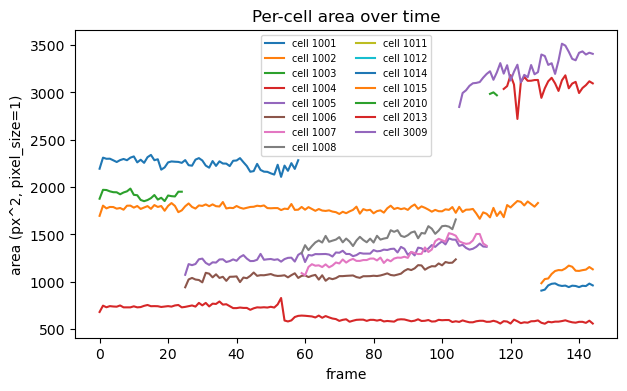

In [9]:
output_csv = REPO_ROOT / "demo" / "quickstart" / "outputs" / "03_measurements_timeseries_demo.csv"
output_csv.parent.mkdir(parents=True, exist_ok=True)
timeseries.to_csv(output_csv, index=False)
print("saved", len(timeseries), "rows to", output_csv)

fig, ax = plt.subplots(figsize=(7, 4))
for label, group in timeseries.groupby("label"):
    ax.plot(group["frame"], group["area"], label=f"cell {int(label)}")
ax.set_xlabel("frame")
ax.set_ylabel("area (px^2, pixel_size=1)")
ax.set_title("Per-cell area over time")
ax.legend(fontsize=7, ncol=2)
plt.show()

A sudden, sustained jump in area (a track's area roughly doubling and then
staying there) is the morphological signature of a fusion/mating event --
compare the frame number where that happens to the `fusion:` events printed
by the tracker in step 2.

## Next steps

This notebook stops at per-cell geometry. `cellmate.mating.CellNetwork`
builds on exactly this kind of tracked-mask + measurement data, combining it
with fluorescence channels to automatically classify each cell's mating
stage over time -- see `demo/tmp/03_image_measure_create_cells.ipynb` for a
real (if informally organized) example of that fuller pipeline.

## Command-line equivalent

```bash
# a single frame
python 03_measure_image.py \
    --input ../YAV2104xYAV2105_20220826_exp011_05_R3D_rigid_003002.tif \
    --mask-channel -1 --frame 0

# every frame, concatenated into one CSV
python 03_measure_image.py --batch --output outputs/measurements.csv
```

Run `python 03_measure_image.py --help` for the full list of options.

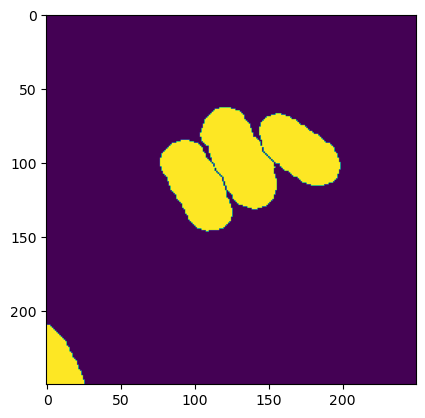

In [10]:
plt.imshow(image[0,4])